# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_:
- _Student No._: 20XX-XXXXX
- _Section_: fill in

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

**Figure 1. Synthetic data interpolation.** Insert a figure comparing the sampled sine data with the linear, nearest, quadratic, and cubic interpolations.

<img src="Interpolation Types.png" alt="Fraction Data" width=95%>

**Figure 2. Real-world data reconstruction.** Insert the four reconstruction plots for sampling levels of 50%, 30%, 10%, and 5%.

<img src="4_Plots.png" alt="Different Fraction" width=95%>

### Report discussion

**Interpolator Comparison:** The interpolation methods have their own pros and cons. Nearest Works well for data points that are close to each other and avoids jumping off of the original curve when two samples are close.

**Interpolator comparison:** Discuss how the interpolation methods differ and which reproduces the underlying function most accurately for the synthetic data.

**Sampling-level comparison:** Discuss how reconstruction quality changes as the number of sampled data points decreases. Mention limitations and any visible artifacts.

### Other comments
- 

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

<function matplotlib.pyplot.show(close=None, block=None)>

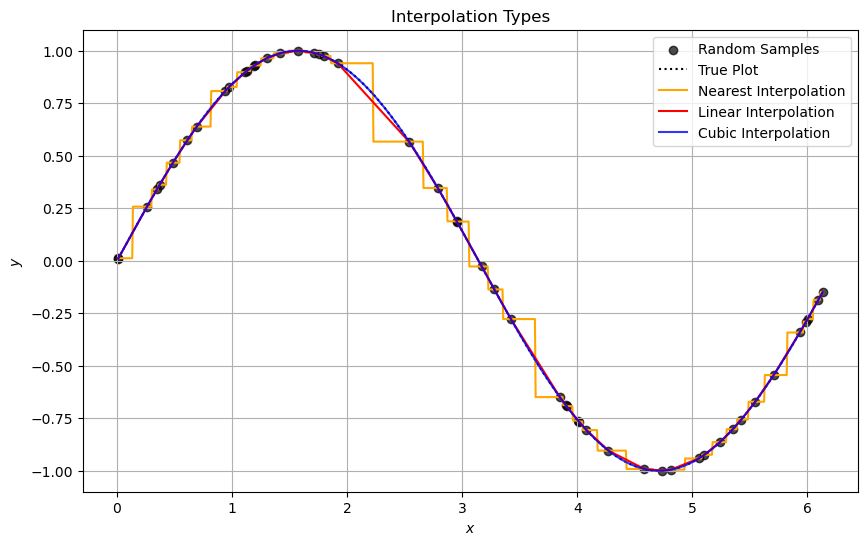

In [2]:
num_samples = 50
x_samples = np.random.uniform(0, 2 * np.pi, num_samples)
y_samples = np.sin(x_samples)

# Sorting into 1-D for interpolation
# apparrently this is very important so that the interpolation knows which points to connect to in order
sort_idx = np.argsort(x_samples)
# argsort outputs a numbered list
# the sorted listed are then built using that ordering
x_sorted = x_samples[sort_idx]
y_sorted = y_samples[sort_idx]

# interpolates between the points we just defined
linear_interpolation = interpolate.interp1d(x_sorted, y_sorted, kind="linear")
nearest_interpolation = interpolate.interp1d(x_sorted, y_sorted, kind="nearest") 
cubic_interpolation = interpolate.interp1d(x_sorted, y_sorted, kind="cubic")

# reconstructing domain
x_eval = np.linspace(x_sorted.min(), x_sorted.max(), 1000)

# 
y_nearest = nearest_interpolation(x_eval)
y_linear = linear_interpolation(x_eval)
y_cubic = cubic_interpolation(x_eval)
y_actual = np.sin(x_eval)

# plotting 
plt.figure(figsize=(10, 6))
plt.scatter(x_sorted, y_sorted, color="Black", alpha=0.7, label="Random Samples")
plt.plot(x_eval, y_actual, color="Black", linestyle=":", label="True Plot")

plt.plot(x_eval, y_nearest, color="Orange", label="Nearest Interpolation")
plt.plot(x_eval, y_linear, color="Red", label="Linear Interpolation")
plt.plot(x_eval, y_cubic, color="Blue", label="Cubic Interpolation", alpha=0.8)

plt.title("Interpolation Types")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.grid()
plt.savefig('Interpolation Types.png', dpi=150)
plt.show

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [3]:
# !wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

<function matplotlib.pyplot.close(fig: "None | int | str | Figure | Literal['all']" = None) -> 'None'>

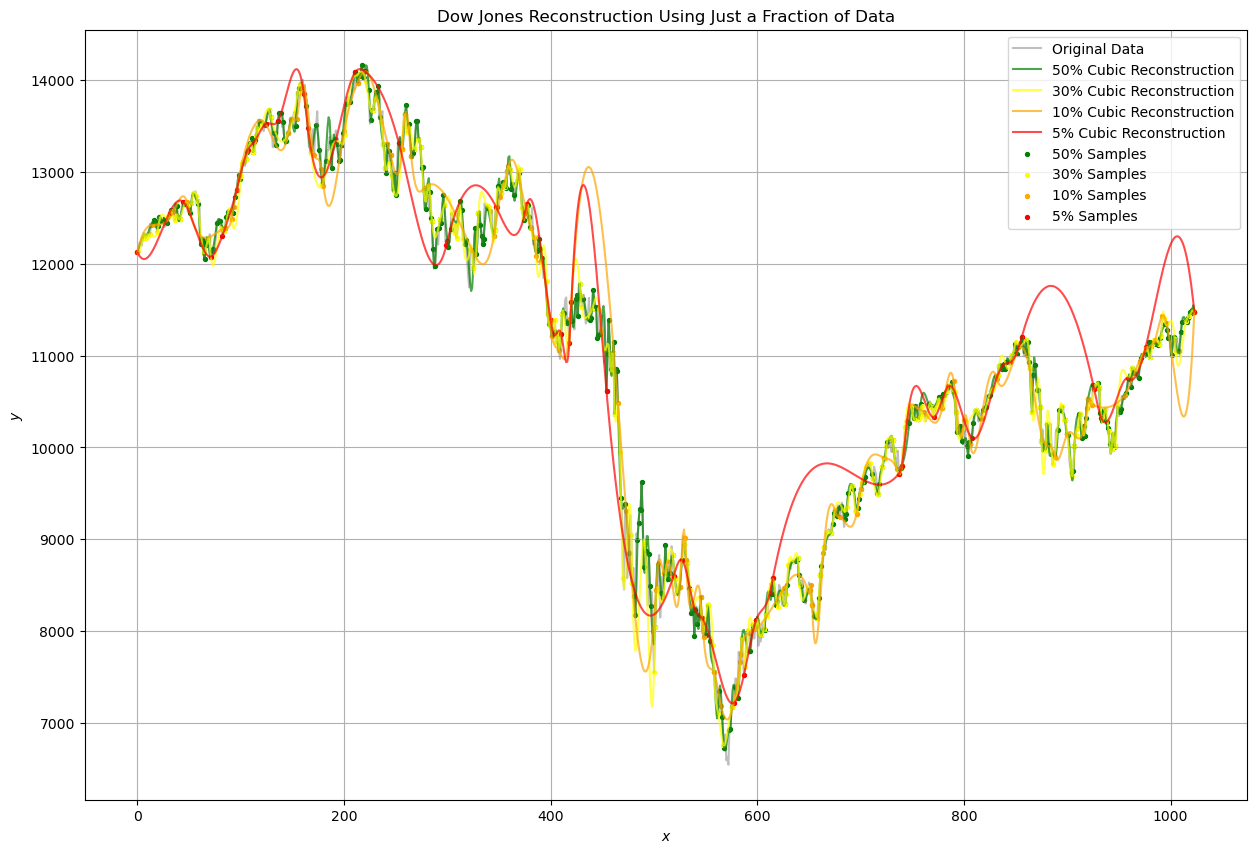

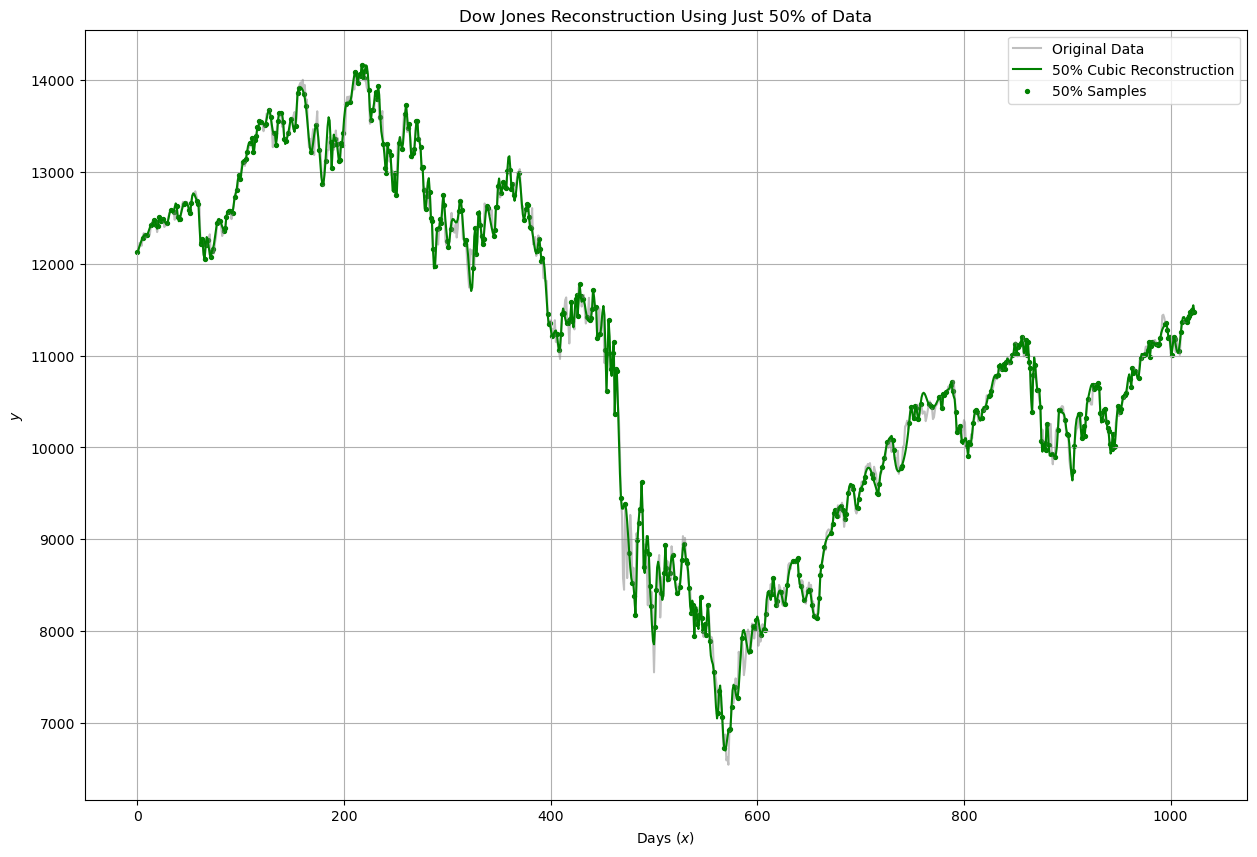

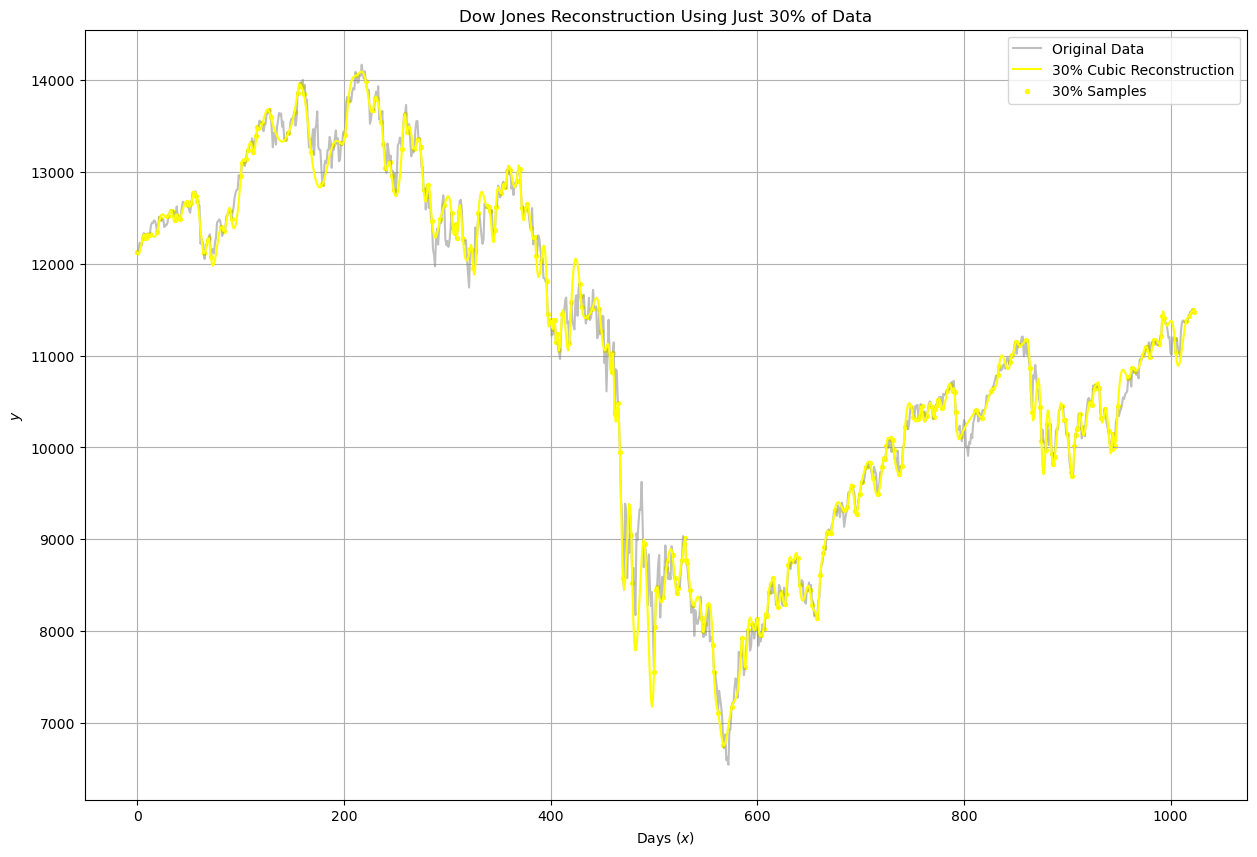

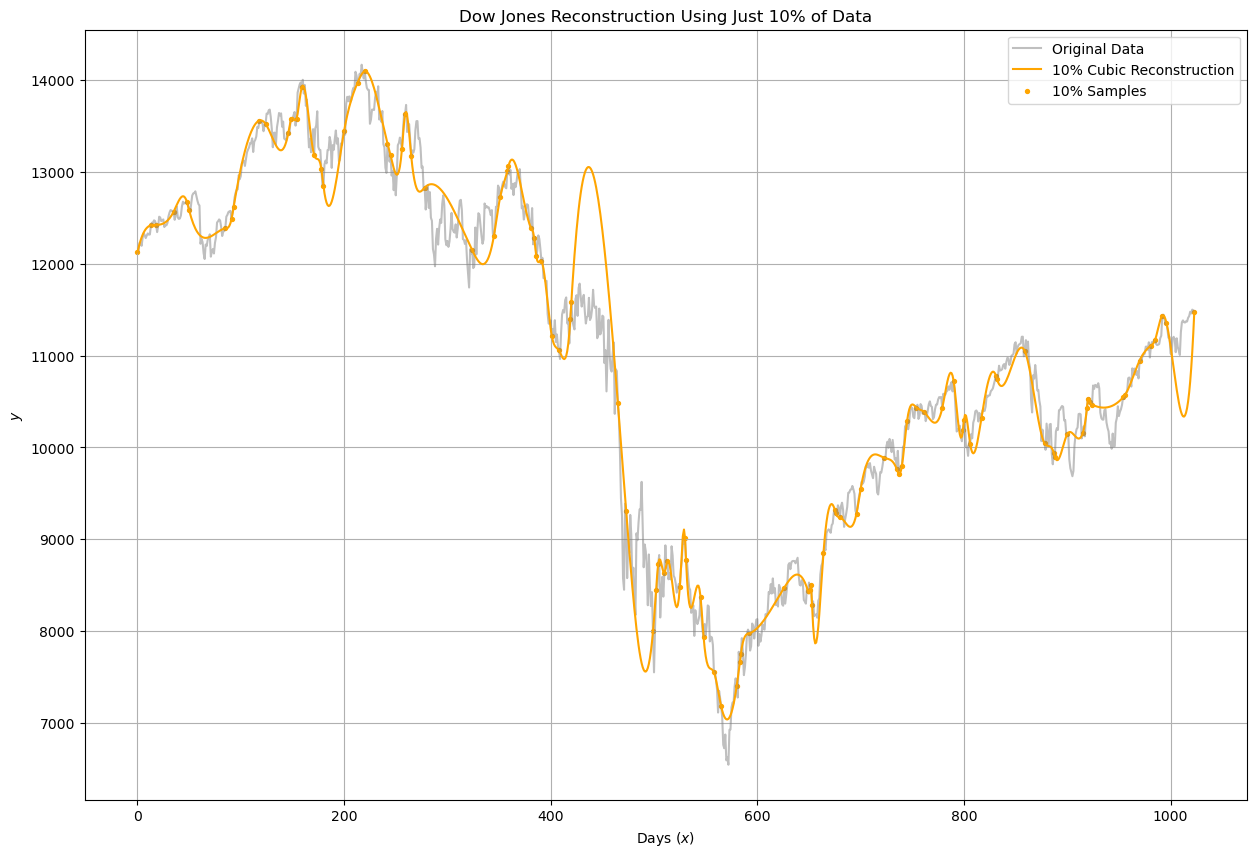

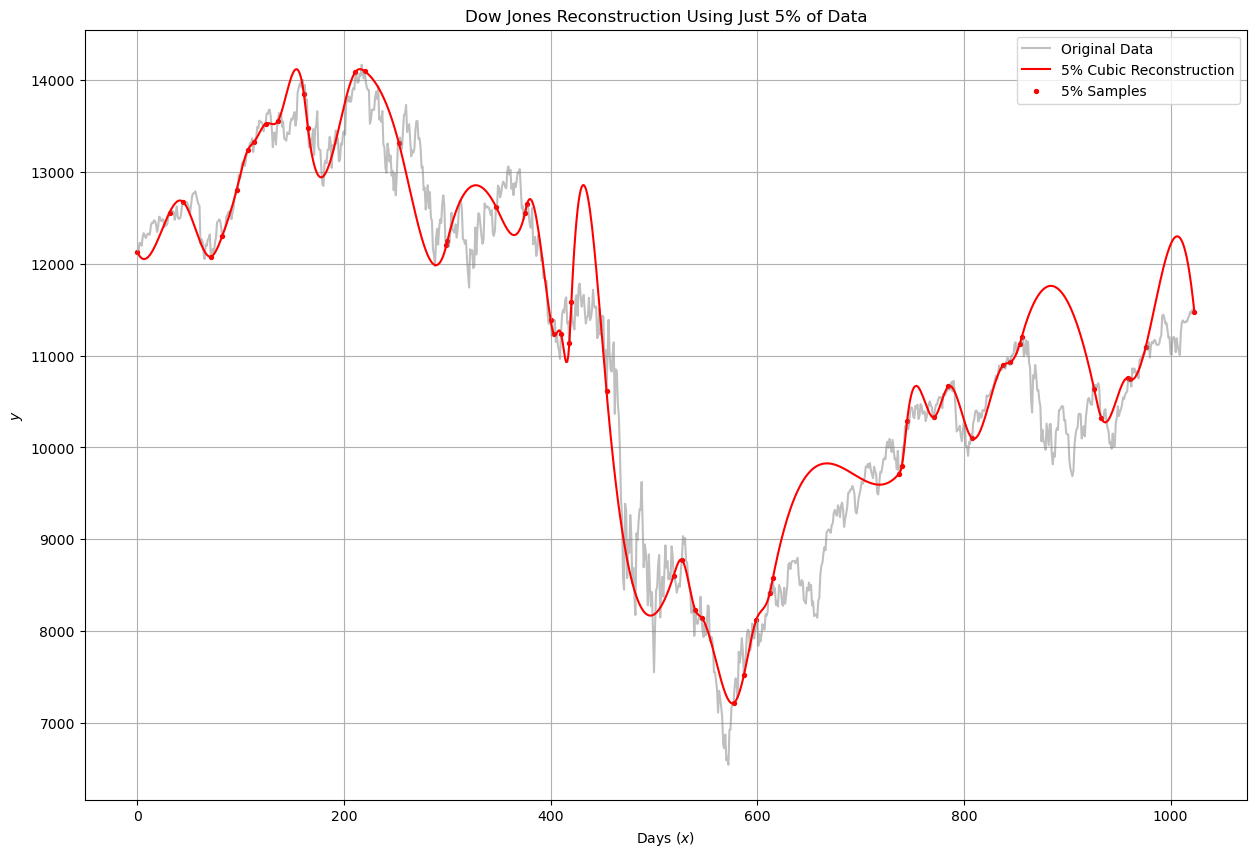

In [4]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

# loads the data from the .txt file into an array
y_data = np.loadtxt("dow.txt")
# generates an array that counts the number of elements inside y_data 
x_data = np.arange(len(y_data))

# setting up the fractions
frac50 = 0.50
frac30 = 0.30
frac10 = 0.10
frac05 = 0.05

# setting the amount of samples for each fraction
num_samples50 = int(len(x_data) * frac50)
num_samples30 = int(len(x_data) * frac30)
num_samples10 = int(len(x_data) * frac10)
num_samples05 = int(len(x_data) * frac05)


# makes sure that the frist and last points still exist ensuring that our data starts and ends at the same place
# this code also sorts the points so that we can plot them correctly
inner_indices50 = rng.choice(x_data[1:-1], size=num_samples50 - 2, replace=False)
sampled_indices50 = np.sort(
    np.concatenate(([0], inner_indices50, [len(x_data) - 1]))
)

inner_indices30 = rng.choice(x_data[1:-1], size=num_samples30 - 2, replace=False)
sampled_indices30 = np.sort(
    np.concatenate(([0], inner_indices30, [len(x_data) - 1]))
)

inner_indices10 = rng.choice(x_data[1:-1], size=num_samples10 - 2, replace=False)
sampled_indices10 = np.sort(
    np.concatenate(([0], inner_indices10, [len(x_data) - 1]))
)

inner_indices05 = rng.choice(x_data[1:-1], size=num_samples05 - 2, replace=False)
sampled_indices05 = np.sort(
    np.concatenate(([0], inner_indices05, [len(x_data) - 1]))
)

# takes a sample ammount equalt to the fraction ammount for each fraction
x_samples50 = x_data[sampled_indices50]
y_samples50 = y_data[sampled_indices50]

x_samples30 = x_data[sampled_indices30]
y_samples30 = y_data[sampled_indices30]

x_samples10 = x_data[sampled_indices10]
y_samples10 = y_data[sampled_indices10]
                     
x_samples05 = x_data[sampled_indices05]
y_samples05 = y_data[sampled_indices05]

# Interpolatng and Reconstructing the Plot for each fraction
f_cubic50 = interpolate.interp1d(x_samples50, y_samples50, kind="cubic")
y_reconstructed50 = f_cubic50(x_data)

f_cubic30 = interpolate.interp1d(x_samples30, y_samples30, kind="cubic")
y_reconstructed30 = f_cubic30(x_data)

f_cubic10 = interpolate.interp1d(x_samples10, y_samples10, kind="cubic")
y_reconstructed10 = f_cubic10(x_data)

f_cubic05 = interpolate.interp1d(x_samples05, y_samples05, kind="cubic")
y_reconstructed05 = f_cubic05(x_data)

# Plotting the Figure For ALl
plt.figure(figsize=(15, 10))

# Plotting Original Data
plt.plot(x_data, y_data, color="gray", alpha=0.5, linewidth=1.5, label="Original Data")

# Plotting reconstructed curves
plt.plot(x_data, y_reconstructed50, color="green", linewidth=1.5, label="50% Cubic Reconstruction", alpha=0.7)
plt.plot(x_data, y_reconstructed30, color="yellow", linewidth=1.5, label="30% Cubic Reconstruction", alpha=0.7)
plt.plot(x_data, y_reconstructed10, color="orange", linewidth=1.5, label="10% Cubic Reconstruction", alpha=0.7)
plt.plot(x_data, y_reconstructed05, color="red", linewidth=1.5, label="5% Cubic Reconstruction", alpha=0.7)

# Plotting the Points that were randomly chosen for each curve
plt.scatter(x_samples50, y_samples50, label="50% Samples", s=8, color="green")
plt.scatter(x_samples30, y_samples30, label="30% Samples", s=8, color="yellow")
plt.scatter(x_samples10, y_samples10, label="10% Samples", s=8, color="orange")
plt.scatter(x_samples05, y_samples05, label="5% Samples", s=8, color="red")

# naming and stuff
plt.title(f"Dow Jones Reconstruction Using Just a Fraction of Data")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.grid()
plt.show
plt.savefig('Fraction_Data.png', dpi=150)
plt.close


#########################3
# Plotting each graph separately

# Plotting the 50% Figure
plt.figure(figsize=(15, 10))

# Plotting Original Data
plt.plot(x_data, y_data, color="gray", alpha=0.5, linewidth=1.5, label="Original Data")

# Plotting reconstructed curves
plt.plot(x_data, y_reconstructed50, color="green", linewidth=1.5, label="50% Cubic Reconstruction")

plt.scatter(x_samples50, y_samples50, label="50% Samples", s=8, color="green")

plt.title(f"Dow Jones Reconstruction Using Just 50% of Data")
plt.xlabel("Days ($x$)")
plt.ylabel("$y$")
plt.legend()
plt.grid()
plt.show
plt.close

# Plotting the 30% Figure
plt.figure(figsize=(15, 10))

# Plotting Original Data
plt.plot(x_data, y_data, color="gray", alpha=0.5, linewidth=1.5, label="Original Data")

# Plotting reconstructed curves
plt.plot(x_data, y_reconstructed30, color="yellow", linewidth=1.5, label="30% Cubic Reconstruction")

plt.scatter(x_samples30, y_samples30, label="30% Samples", s=8, color="yellow")

plt.title(f"Dow Jones Reconstruction Using Just 30% of Data")
plt.xlabel("Days ($x$)")
plt.ylabel("$y$")
plt.legend()
plt.grid()
plt.show
plt.close

# Plotting the 10% Figure
plt.figure(figsize=(15, 10))

# Plotting Original Data
plt.plot(x_data, y_data, color="gray", alpha=0.5, linewidth=1.5, label="Original Data")

# Plotting reconstructed curves
plt.plot(x_data, y_reconstructed10, color="orange", linewidth=1.5, label="10% Cubic Reconstruction")

plt.scatter(x_samples10, y_samples10, label="10% Samples", s=8, color="orange")

plt.title(f"Dow Jones Reconstruction Using Just 10% of Data")
plt.xlabel("Days ($x$)")
plt.ylabel("$y$")
plt.legend()
plt.grid()
plt.show
plt.close

# Plotting the 05% Figure
plt.figure(figsize=(15, 10))

# Plotting Original Data
plt.plot(x_data, y_data, color="gray", alpha=0.5, linewidth=1.5, label="Original Data")

# Plotting reconstructed curves
plt.plot(x_data, y_reconstructed05, color="red", linewidth=1.5, label="5% Cubic Reconstruction")

plt.scatter(x_samples05, y_samples05, label="5% Samples", s=8, color="red")

plt.title(f"Dow Jones Reconstruction Using Just 5% of Data")
plt.xlabel("Days ($x$)")
plt.ylabel("$y$")
plt.legend()
plt.grid()
plt.show
plt.close

<function matplotlib.pyplot.close(fig: "None | int | str | Figure | Literal['all']" = None) -> 'None'>

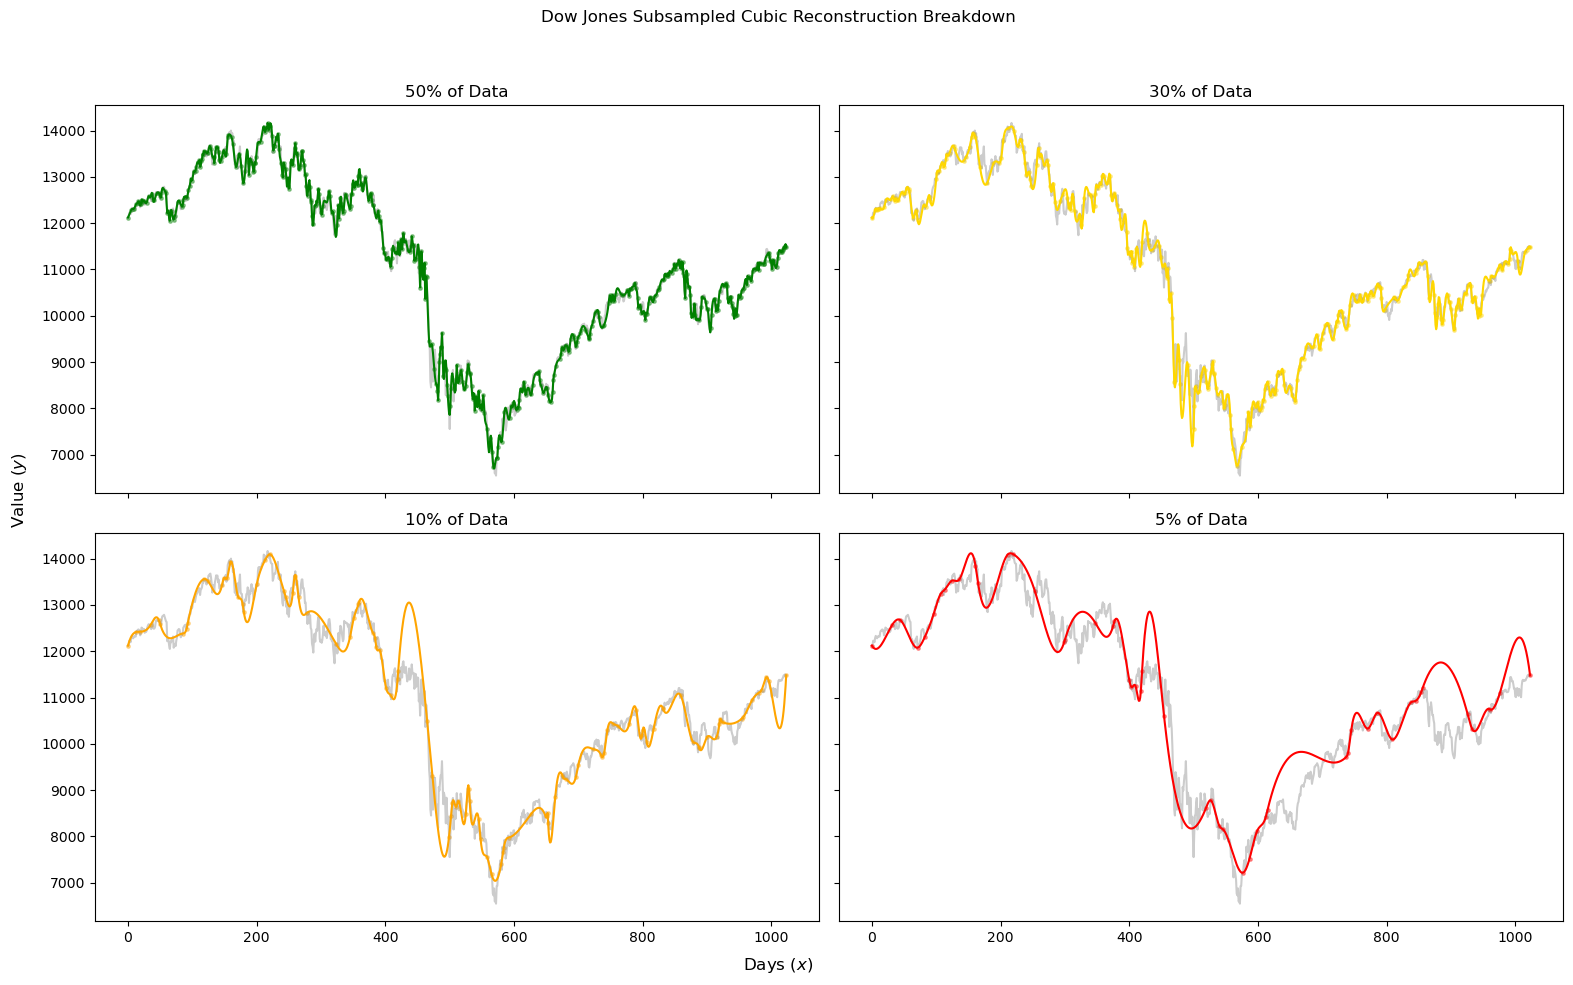

In [7]:
#  makes 2x2 grid
# sharey makes sure that they share a grid so data lines up
fig, axes = plt.subplots(2, 2, figsize=(16, 10), sharex=True, sharey=True)
axes = axes.flatten()  # Flattens into a 1D list: [Top-Left, Top-Right, Bottom-Left, Bottom-Right]

# top left 50%
axes[0].plot(x_data, y_data, color="gray", alpha=0.4, label="Original Data")
axes[0].plot(x_data, y_reconstructed50, color="green", label="50% Reconstruction")
axes[0].scatter(x_samples50, y_samples50, s=6, color="green", alpha=0.4, label="50% Samples")
axes[0].set_title("50% of Data")
axes[0].legend
axes[0].grid

# top right 30%
axes[1].plot(x_data, y_data, color="gray", alpha=0.4, label="Original Data")
axes[1].plot(x_data, y_reconstructed30, color="gold", label="30% Reconstruction")
axes[1].scatter(x_samples30, y_samples30, s=6, color="gold", alpha=0.4, label="30% Samples")
axes[1].set_title("30% of Data")
axes[1].legend
axes[1].grid

# bottom left 10%
axes[2].plot(x_data, y_data, color="gray", alpha=0.4, label="Original Data")
axes[2].plot(x_data, y_reconstructed10, color="orange", label="10% Reconstruction")
axes[2].scatter(x_samples10, y_samples10, s=6, color="orange", alpha=0.4, label="10% Samples")
axes[2].set_title("10% of Data")
axes[2].legend
axes[2].grid

# bottom right 5%
axes[3].plot(x_data, y_data, color="gray", alpha=0.4, label="Original Data")
axes[3].plot(x_data, y_reconstructed05, color="red", label="5% Reconstruction")
axes[3].scatter(x_samples05, y_samples05, s=6, color="red", alpha=0.4, label="5% Samples")
axes[3].set_title("5% of Data")
axes[3].legend
axes[3].grid

# Global labels and spacing configurations
plt.suptitle("Dow Jones Subsampled Cubic Reconstruction Breakdown")
fig.text(0.5, 0.02, "Days ($x$)", ha="center", fontsize=12)
fig.text(0.02, 0.5, "Value ($y$)", va="center", rotation="vertical", fontsize=12)
plt.tight_layout(rect=[0.03, 0.03, 1, 0.95])

plt.show
plt.savefig('4_Plots.png', dpi=150)
plt.close

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

<function matplotlib.pyplot.close(fig: "None | int | str | Figure | Literal['all']" = None) -> 'None'>

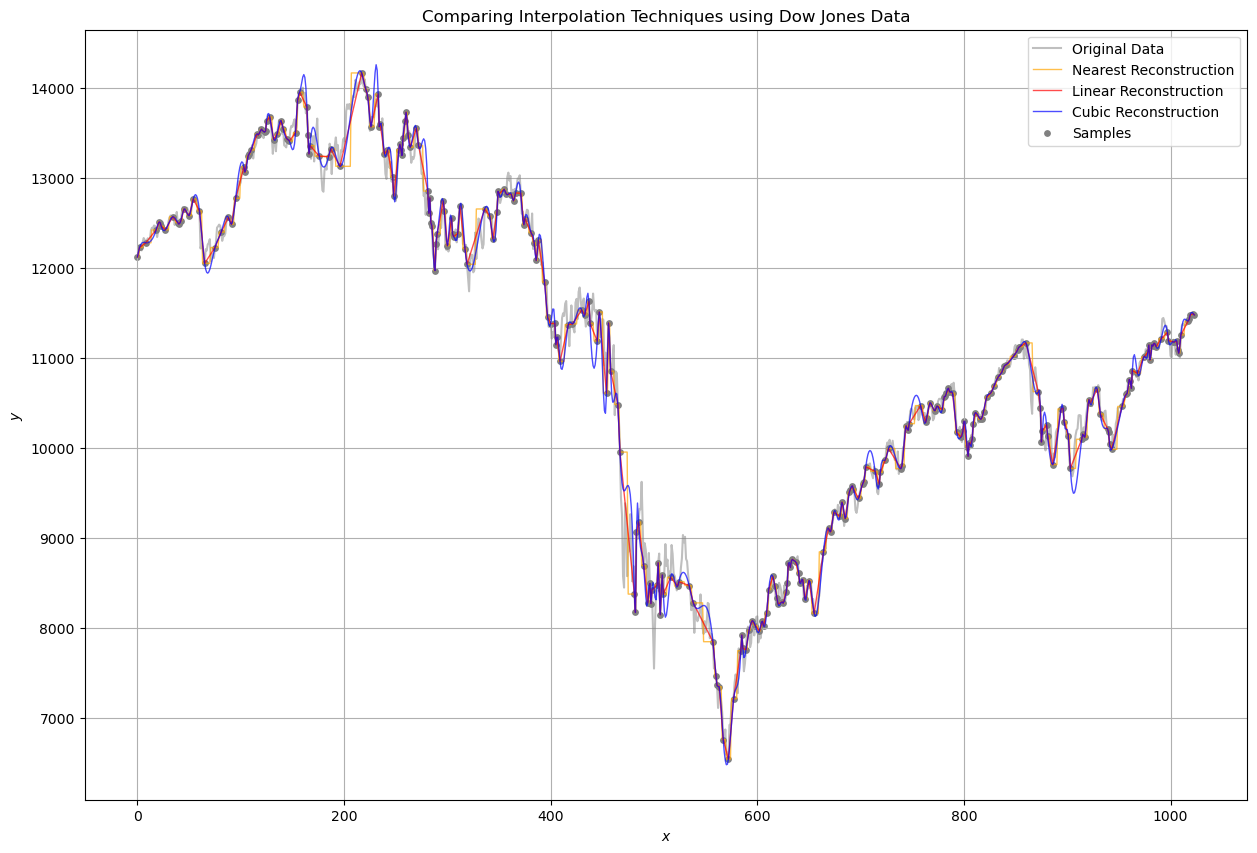

In [6]:
# loads the data from the .txt file into an array
y_data = np.loadtxt("dow.txt")
# generates an array that counts the number of elements inside y_data 
x_data = np.arange(len(y_data))

# Set Fraction Percentage Here ! ! !
frac = 0.30

# setting the amount of samples for each fraction
num_samples = int(len(x_data) * frac)

# makes sure that the frist and last points still exist ensuring that our data starts and ends at the same place
# this code also sorts the points so that we can plot them correctly
inner_indices = rng.choice(x_data[1:-1], size=num_samples - 2, replace=False)
sampled_indices = np.sort(
    np.concatenate(([0], inner_indices, [len(x_data) - 1]))
)

# takes a sample ammount equalt to the fraction ammount
x_samples = x_data[sampled_indices]
y_samples = y_data[sampled_indices]

# Interpolatng and Reconstructing the Plot for each fraction
f_nearest = interpolate.interp1d(x_samples, y_samples, kind="nearest")
f_linear = interpolate.interp1d(x_samples, y_samples, kind="linear")
f_cubic = interpolate.interp1d(x_samples, y_samples, kind="cubic")

y_reconstructed_nearest = f_nearest(x_data)
y_reconstructed_linear = f_linear(x_data)
y_reconstructed_cubic = f_cubic(x_data)
    
# Plotting the Figure
plt.figure(figsize=(15, 10))

# Plotting Original Data
plt.plot(x_data, y_data, color="gray", alpha=0.5, linewidth=1.5, label="Original Data")

# Plotting reconstructed curves
plt.plot(x_data, y_reconstructed_nearest, color="orange", linewidth=1.0, label="Nearest Reconstruction", alpha=0.7)
plt.plot(x_data, y_reconstructed_linear, color="red", linewidth=1.0, label="Linear Reconstruction", alpha=0.7)
plt.plot(x_data, y_reconstructed_cubic, color="blue", linewidth=1.0, label="Cubic Reconstruction", alpha=0.7)

# Plotting the Points that were randomly chosen for each curve
plt.scatter(x_samples, y_samples, label="Samples", s=15, color="Grey")


# naming and stuff
plt.title(f"Comparing Interpolation Techniques using Dow Jones Data")
plt.xlabel("$x$")
plt.ylabel("$y$")
plt.legend()
plt.grid()
plt.show
plt.savefig('Comparison.png', dpi=150)
plt.close

### Problem  code summary

The three problems follow almost the same structure. They start by defining our data set and setting a specified amount of data points to use for reconstruction. After which the data is sorted and arranged to ensure proper ordering. Next our interpolation techniques are applied to the data samples. Finally the original data is plotted against our reconstructed data and shown in a figure.